# Comprehensive Data Science Analysis: SGRH Lung Cancer ICI Cohort
### Evaluation of Responders vs. Non-Responders to Immune Checkpoint Inhibitor Therapy
**Dataset:** `data/raw/ICI.xlsx` ($N = 64$ patients, 146 raw columns)  
**Methodology:** Strict empirical verification, hypothesis testing with Multiple Testing Correction (FDR), clinical logic sanity checks, and batch-effect diagnosis.

---

## 1. Study Overview & Analytical Objectives
This notebook conducts a rigorous, end-to-end exploratory data analysis (EDA) and data quality audit of the Sir Ganga Ram Hospital (SGRH) Lung Cancer immunotherapy dataset.
Key objectives:
1. **Schema & Data Ingestion Audit:** Characterize raw structures, dimensions, types, and column nomenclature.
2. **Data Quality & Hygiene Audit:** Detect whitespace anomalies, data entry typos, rounding discrepancies, and categorical encoding issues.
3. **Clinical & Survival Logic Verification:** Test fundamental oncological constraints ($PFS \le OS$, event encoding, staging vs. metastasis, histological exclusivity).
4. **Hematological & Inflammatory Dynamics:** Assess baseline and post-therapy Complete Blood Count (CBC) and Neutrophil-to-Lymphocyte Ratio (NLR) kinetics.
5. **Multi-Omics Profiling:** Profile 92-plex Immuno-Oncology proteomics (Olink NPX) and 5-plex metabolomics with non-parametric Mann-Whitney U tests and Benjamini-Hochberg FDR correction.
6. **Instrument Run-Order & Batch Drift Diagnosis:** Investigate potential sample ordering confounding and instrument signal drift.
7. **Actionable Preprocessing Recommendations:** Define formal data cleaning specifications for downstream machine learning and biomarker modeling.


In [1]:
import os
import sys
import hashlib
import numpy as np
import pandas as pd
import scipy.stats as stats
import matplotlib.pyplot as plt
import seaborn as sns

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.size'] = 10
plt.rcParams['axes.labelsize'] = 11
plt.rcParams['axes.titlesize'] = 12

print("Required libraries successfully imported.")


Required libraries successfully imported.


## 2. Data Ingestion & Cryptographic Integrity Check

In [2]:
raw_data_path = os.path.join('..', 'data', 'raw', 'ICI.xlsx')
if not os.path.exists(raw_data_path):
    # Fallback to absolute path if running from different working directory
    raw_data_path = r'c:\Users\SAM\Documents\GitHub\SGRH-Lung Cancer\data\raw\ICI.xlsx'

with open(raw_data_path, 'rb') as f:
    file_bytes = f.read()
sha256_hash = hashlib.sha256(file_bytes).hexdigest()

print(f"File Size: {len(file_bytes):,} bytes")
print(f"SHA-256 Checksum: {sha256_hash}")

# Load raw dataset
df_raw = pd.read_excel(raw_data_path)
print(f"Dataset Dimensions: {df_raw.shape[0]} rows (patients) x {df_raw.shape[1]} columns")


File Size: 96,786 bytes
SHA-256 Checksum: e19a9838f55ed4a7890c743a9d6ac03d12b3b82d6fb53de9ea1db0d02eff3496


Dataset Dimensions: 64 rows (patients) x 146 columns


## 3. Data Quality, Hygiene & Anomaly Audit
Here we audit the dataset for:
- Trailing whitespace in column headers and string variables.
- Missingness (explicit and implicit).
- Non-numeric typos in categorical/binary columns.
- Mathematical consistency in derived anthropometric indices (BMI).


In [3]:
# 1. Column header whitespace check
whitespace_headers = [c for c in df_raw.columns if c != c.strip()]
print(f"Column headers with leading/trailing whitespaces: {len(whitespace_headers)} / {len(df_raw.columns)}")
for c in whitespace_headers[:10]:
    print(f"  Raw: {repr(c)} -> Cleaned: {repr(c.strip())}")

# 2. Check for explicit missing values
null_counts = df_raw.isna().sum()
cols_with_nulls = null_counts[null_counts > 0]
print(f"\nColumns with explicit null (NaN) values: {len(cols_with_nulls)}")

# 3. Categorical string inspection: 'sex'
print(f"\nUnique values in 'sex': {[repr(x) for x in df_raw['sex'].unique()]}")
sex_ws = df_raw[df_raw['sex'].astype(str).str.contains(' ')]
print(f"Samples with trailing whitespace in 'sex': {sex_ws[['sample ', 'sex']].to_dict(orient='records')}")

# 4. Binary column typo inspection: 'non-veg.'
non_veg_col = [c for c in df_raw.columns if 'non-veg' in c.lower()][0]
print(f"\nValue counts in '{non_veg_col}':")
print(df_raw[non_veg_col].value_counts(dropna=False))
bad_nonveg = df_raw[df_raw[non_veg_col].astype(str) == '1`']
print(f"Sample with backtick typo '1`': {bad_nonveg[['sample ', non_veg_col]].to_dict(orient='records')}")


Column headers with leading/trailing whitespaces: 22 / 146
  Raw: 'sample ' -> Cleaned: 'sample'
  Raw: 'Hypertension ' -> Cleaned: 'Hypertension'
  Raw: 'SMOKING ' -> Cleaned: 'SMOKING'
  Raw: 'CANCER/TYPE ' -> Cleaned: 'CANCER/TYPE'
  Raw: 'WEIGHT LOSS ' -> Cleaned: 'WEIGHT LOSS'
  Raw: 'PLEURAL EFFUSION ' -> Cleaned: 'PLEURAL EFFUSION'
  Raw: 'PRE-TREATED RADIOTHERAPY ' -> Cleaned: 'PRE-TREATED RADIOTHERAPY'
  Raw: 'PRE-TREATED CHEMOTHERAPY ' -> Cleaned: 'PRE-TREATED CHEMOTHERAPY'
  Raw: 'ADENOCARCINOMA ' -> Cleaned: 'ADENOCARCINOMA'
  Raw: 'SQUAMOUS CELL CARCINOMA ' -> Cleaned: 'SQUAMOUS CELL CARCINOMA'

Columns with explicit null (NaN) values: 0

Unique values in 'sex': ["'M'", "'F'", "'F '"]
Samples with trailing whitespace in 'sex': [{'sample ': 10, 'sex': 'F '}]

Value counts in 'non-veg.':
non-veg.
1     35
0     28
1`     1
Name: count, dtype: int64
Sample with backtick typo '1`': [{'sample ': 40, 'non-veg.': '1`'}]


In [4]:
# 5. Anthropometric audit: Calculated BMI vs Recorded BMI
calc_bmi = df_raw['weight'] / ((df_raw['height'] / 100.0) ** 2)
bmi_discrepancy = np.abs(df_raw['BMI'] - calc_bmi)
discrepant_bmi_pts = df_raw[bmi_discrepancy > 1.0].copy()
discrepant_bmi_pts['calc_bmi'] = calc_bmi[bmi_discrepancy > 1.0]
discrepant_bmi_pts['bmi_error'] = df_raw['BMI'] - calc_bmi

print(f"Patients with |BMI_recorded - BMI_calculated| > 1.0 kg/m^2: {len(discrepant_bmi_pts)}")
print(discrepant_bmi_pts[['sample ', 'height', 'weight', 'BMI', 'calc_bmi', 'bmi_error']])

# 6. Diet survey logical contradiction: Veg vs Non-Veg
veg_col = [c for c in df_raw.columns if c.strip().lower() == 'veg.'][0]
crosstab_diet = pd.crosstab(df_raw[veg_col], df_raw[non_veg_col].astype(str), rownames=['Veg.'], colnames=['Non-Veg.'])
print(f"\nDiet Cross-Tabulation:")
print(crosstab_diet)
dual_diet_pts = (df_raw[veg_col] == 1) & (df_raw[non_veg_col].astype(str).isin(['1', '1`']))
print(f"Patients recorded as BOTH Veg=1 and Non-Veg=1: {dual_diet_pts.sum()} / {len(df_raw)}")


Patients with |BMI_recorded - BMI_calculated| > 1.0 kg/m^2: 8
    sample   height  weight  BMI   calc_bmi  bmi_error
3         4     172      77   25  26.027582  -1.027582
4         5     157      63   28  25.558846   2.441154
27       28     175      74   23  24.163265  -1.163265
30       31     165      70   27  25.711662   1.288338
38       39     180      70   29  21.604938   7.395062
39       40     167      68   23  24.382373  -1.382373
40       41     167      74   25  26.533759  -1.533759
43       44     167      85   29  30.477966  -1.477966

Diet Cross-Tabulation:
Non-Veg.   0   1  1`
Veg.                
0          0   5   0
1         28  30   1
Patients recorded as BOTH Veg=1 and Non-Veg=1: 31 / 64


## 4. Clinical Staging, Drug Allocation & Survival Logic Audit
In clinical oncology:
1. **Progression-Free Survival (PFS)** is defined as the time from treatment initiation until objective disease progression or death from any cause.
2. **Overall Survival (OS)** is the time from treatment initiation until death from any cause.
3. Therefore, biologically and mathematically, **$PFS \le OS$** must hold true for all patients.


In [5]:
pfs_col = 'PFS (DAYS)'
os_col = 'OS (DAYS)'
recc_col = 'RECC. YES(1)/NO(0)'
death_col = 'DEATH (0)/ALIVE(1)'
label_col = df_raw.columns[1]

# Check PFS <= OS constraint
pfs_os_violation = df_raw[df_raw[pfs_col] > df_raw[os_col]][['sample ', label_col, pfs_col, os_col, recc_col, death_col]].copy()
pfs_os_violation['excess_pfs_days'] = pfs_os_violation[pfs_col] - pfs_os_violation[os_col]

print(f"CRITICAL FINDING: Number of patients violating PFS <= OS: {len(pfs_os_violation)}")
print(pfs_os_violation.to_string(index=False))

# Survival Summary Statistics
print(f"\nPFS (Days): Min={df_raw[pfs_col].min()}, Median={df_raw[pfs_col].median()}, Max={df_raw[pfs_col].max()}")
print(f"OS (Days): Min={df_raw[os_col].min()}, Median={df_raw[os_col].median()}, Max={df_raw[os_col].max()}")
print(f"\nEvent Cross-Tabulation (Label vs Vital Status [0=Death, 1=Alive]):")
print(pd.crosstab(df_raw[label_col], df_raw[death_col], rownames=['Response Label'], colnames=['DEATH(0)/ALIVE(1)']))
print(f"\nEvent Cross-Tabulation (Label vs Recurrence [0=No, 1=Yes]):")
print(pd.crosstab(df_raw[label_col], df_raw[recc_col], rownames=['Response Label'], colnames=['Recurrence']))


CRITICAL FINDING: Number of patients violating PFS <= OS: 4
 sample  label (NR= Non-responder, R= Responder)  PFS (DAYS)  OS (DAYS)  RECC. YES(1)/NO(0)  DEATH (0)/ALIVE(1)  excess_pfs_days
       1                                      NR          58         19                   1                   0               39
      21                                      NR          41         33                   1                   0                8
      28                                      NR          72         41                   1                   0               31
      53                                       R        1404       1265                   1                   1              139

PFS (Days): Min=16, Median=141.0, Max=1404
OS (Days): Min=19, Median=257.0, Max=1300

Event Cross-Tabulation (Label vs Vital Status [0=Death, 1=Alive]):
DEATH(0)/ALIVE(1)   0   1
Response Label           
NR                 30   0
R                  21  13

Event Cross-Tabulation (Label vs Rec

C:\Users\SAM\AppData\Local\Temp\ipykernel_16464\2706905954.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x=label_col, y=pfs_col, palette=['#e74c3c', '#2ecc71'], ax=axes[0])
C:\Users\SAM\AppData\Local\Temp\ipykernel_16464\2706905954.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_raw, x=label_col, y=os_col, palette=['#e74c3c', '#2ecc71'], ax=axes[1])


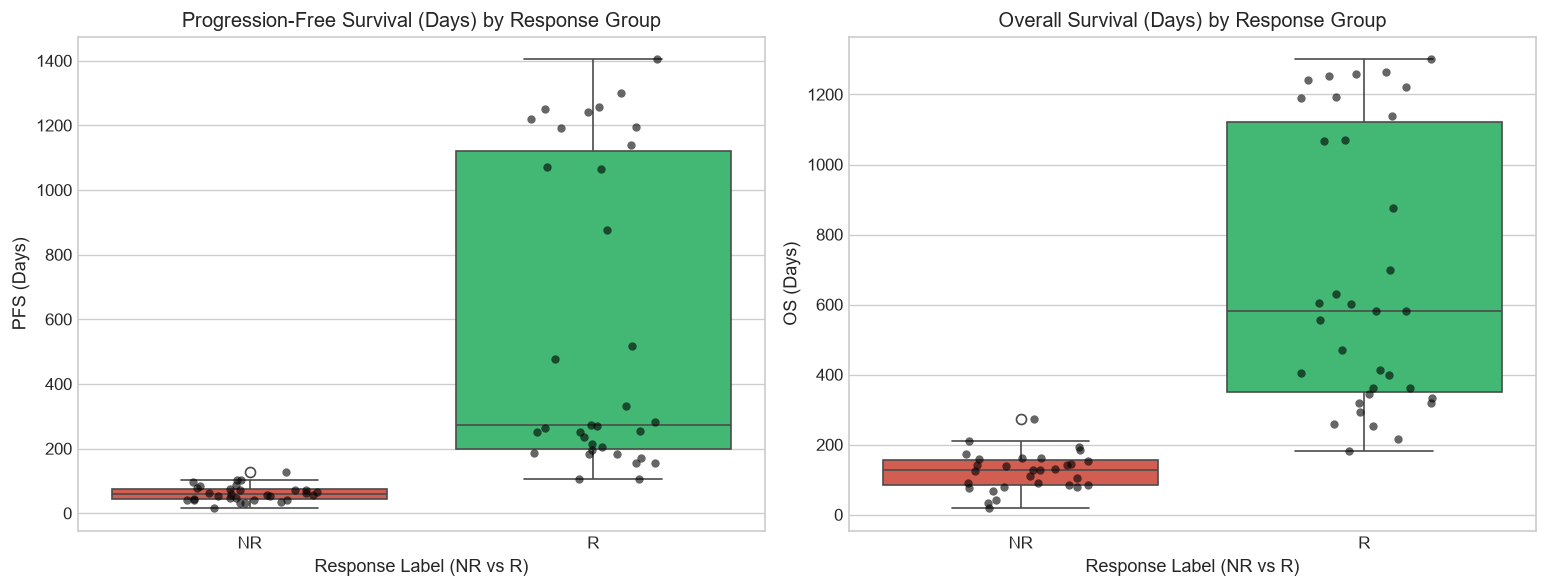

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# PFS boxplot
sns.boxplot(data=df_raw, x=label_col, y=pfs_col, palette=['#e74c3c', '#2ecc71'], ax=axes[0])
sns.stripplot(data=df_raw, x=label_col, y=pfs_col, color='black', alpha=0.6, jitter=0.2, ax=axes[0])
axes[0].set_title('Progression-Free Survival (Days) by Response Group')
axes[0].set_xlabel('Response Label (NR vs R)')
axes[0].set_ylabel('PFS (Days)')

# OS boxplot
sns.boxplot(data=df_raw, x=label_col, y=os_col, palette=['#e74c3c', '#2ecc71'], ax=axes[1])
sns.stripplot(data=df_raw, x=label_col, y=os_col, color='black', alpha=0.6, jitter=0.2, ax=axes[1])
axes[1].set_title('Overall Survival (Days) by Response Group')
axes[1].set_xlabel('Response Label (NR vs R)')
axes[1].set_ylabel('OS (Days)')

plt.tight_layout()
plt.show()


In [7]:
# Drug distribution
print("Immune Checkpoint Inhibitor Allocation:")
print(f"  Nivolumab: {df_raw['NIVOLUMAB '].sum()} patients ({df_raw['NIVOLUMAB '].mean()*100:.1f}%)")
print(f"  Pembrolizumab: {df_raw['PEMBROLIZUMAB '].sum()} patients ({df_raw['PEMBROLIZUMAB '].mean()*100:.1f}%)")
print(f"  Dual Administration: {((df_raw['NIVOLUMAB ']==1) & (df_raw['PEMBROLIZUMAB ']==1)).sum()} patients")

# Staging & Metastasis
stage_col = [c for c in df_raw.columns if 'stage' in c.lower()][0]
print(f"\nDisease Staging vs Metastasis:")
print(pd.crosstab(df_raw[stage_col], df_raw['Metastasis'], rownames=['Disease Stage'], colnames=['Metastasis']))

# Histology audit
hist_cols = ['ADENOCARCINOMA ', 'SQUAMOUS CELL CARCINOMA ', 'LARGE CELL CARCINOMA ']
hist_sum = df_raw[hist_cols].sum(axis=1)
print(f"\nHistology Flags per Patient Distribution:")
print(hist_sum.value_counts().sort_index())


Immune Checkpoint Inhibitor Allocation:
  Nivolumab: 38 patients (59.4%)
  Pembrolizumab: 26 patients (40.6%)
  Dual Administration: 0 patients

Disease Staging vs Metastasis:
Metastasis      0   1
Disease Stage        
III            38   1
IV              0  25

Histology Flags per Patient Distribution:
0     7
1    49
2     8
Name: count, dtype: int64


## 5. Hematology & Systemic Inflammatory Biomarkers (CBC & NLR)
Evaluating complete blood count differentials at baseline vs. post-therapy, and verifying the Neutrophil-to-Lymphocyte Ratio (NLR).


Max difference between recorded BASELINE RATIO and Neutrophils/Lymphocytes: 0.0097
Baseline leukocyte differential sum: min=61.2%, median=96.2%, max=129.0%
Post-therapy leukocyte differential sum: min=79.9%, median=104.2%, max=159.6%


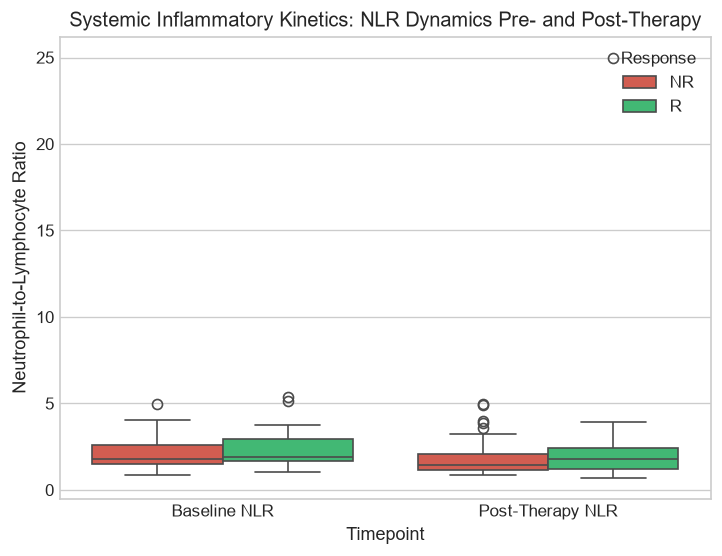

In [8]:
# Verify baseline NLR formula
calc_base_nlr = df_raw['NEUTROPHILS '] / df_raw['LYPHOCYTES PERCENTAGE ']
base_nlr_diff = np.abs(df_raw['BASELINE RATIO'] - calc_base_nlr)
print(f"Max difference between recorded BASELINE RATIO and Neutrophils/Lymphocytes: {base_nlr_diff.max():.4f}")

# Differential sum checks
diff_base = df_raw['NEUTROPHILS '] + df_raw['LYPHOCYTES PERCENTAGE '] + df_raw['MONOCYTES '] + df_raw['EOSINOPHILS ']
diff_post = df_raw['NEUTROPHILS .1'] + df_raw['LYPHOCYTES PERCENTAGE .1'] + df_raw['MONOCYTES .1'] + df_raw['EOSINOPHILS .1']

print(f"Baseline leukocyte differential sum: min={diff_base.min():.1f}%, median={diff_base.median():.1f}%, max={diff_base.max():.1f}%")
print(f"Post-therapy leukocyte differential sum: min={diff_post.min():.1f}%, median={diff_post.median():.1f}%, max={diff_post.max():.1f}%")

# NLR change comparison (Baseline vs Post)
fig, ax = plt.subplots(figsize=(7, 5))
df_nlr = pd.DataFrame({
    'Baseline NLR': df_raw['BASELINE RATIO'],
    'Post-Therapy NLR': df_raw['AFTER THERAPY RATIO '],
    'Response': df_raw[label_col]
})
sns.boxplot(data=pd.melt(df_nlr, id_vars=['Response'], var_name='Timepoint', value_name='NLR'), 
            x='Timepoint', y='NLR', hue='Response', palette=['#e74c3c', '#2ecc71'], ax=ax)
ax.set_title('Systemic Inflammatory Kinetics: NLR Dynamics Pre- and Post-Therapy')
ax.set_ylabel('Neutrophil-to-Lymphocyte Ratio')
plt.show()


## 6. Multi-Omics Profiling: Proteomics (92-Plex) & Metabolomics (5-Plex)
Performing rigorous non-parametric hypothesis testing (Mann-Whitney U) across all quantitative markers with **Benjamini-Hochberg False Discovery Rate (FDR)** control.


In [9]:
metab_cols = ['Thio-Urea', 'Gentisic acid', 'Sphingosine 1-phosphate', 'glutathione', '4-Hydroxy-butanone']
prot_cols = list(df_raw.columns[54:146])
biom_cols = ['TMB (>10 is considered for therapy', 'PDL-1 EXPRESSION ']

all_test_features = biom_cols + metab_cols + prot_cols
r_group = df_raw[df_raw[label_col] == 'R']
nr_group = df_raw[df_raw[label_col] == 'NR']

diff_results = []
for feat in all_test_features:
    r_vals = r_group[feat].dropna()
    nr_vals = nr_group[feat].dropna()
    stat, pval = stats.mannwhitneyu(r_vals, nr_vals, alternative='two-sided')
    r_med = r_vals.median()
    nr_med = nr_vals.median()
    log2fc = np.log2((r_med + 1e-9) / (nr_med + 1e-9)) if nr_med > 0 and r_med > 0 else np.nan
    diff_results.append({
        'feature': feat,
        'R_median': r_med,
        'NR_median': nr_med,
        'log2FC': log2fc,
        'p_value': pval
    })

res_df = pd.DataFrame(diff_results)
res_df['rank'] = res_df['p_value'].rank()
res_df['fdr_bh'] = np.minimum(1.0, res_df['p_value'] * len(res_df) / res_df['rank'])
res_df = res_df.sort_values('p_value').reset_index(drop=True)

print(f"Total features evaluated: {len(res_df)}")
print(f"Features significant at unadjusted p < 0.05: {(res_df['p_value'] < 0.05).sum()}")
print(f"Features significant at Benjamini-Hochberg FDR q < 0.10: {(res_df['fdr_bh'] < 0.10).sum()}")
print(f"Features significant at Benjamini-Hochberg FDR q < 0.05: {(res_df['fdr_bh'] < 0.05).sum()}")

print("\nTop 15 Candidate Biomarkers:")
print(res_df.head(15)[['feature', 'R_median', 'NR_median', 'log2FC', 'p_value', 'fdr_bh']])


Total features evaluated: 99
Features significant at unadjusted p < 0.05: 39
Features significant at Benjamini-Hochberg FDR q < 0.10: 26
Features significant at Benjamini-Hochberg FDR q < 0.05: 13

Top 15 Candidate Biomarkers:
                               feature      R_median     NR_median    log2FC  \
0                    PDL-1 EXPRESSION   6.000000e+01  0.000000e+00       NaN   
1                   4-Hydroxy-butanone  4.612696e+04  1.972782e+05 -2.096549   
2   TMB (>10 is considered for therapy  1.350000e+01  3.150000e+00  2.099536   
3                          glutathione  3.318988e+05  4.093811e+06 -3.624629   
4                        Gentisic acid  1.478968e+06  4.618659e+06 -1.642883   
5                            Thio-Urea  9.914154e+04  3.627950e+04  1.450335   
6                                PD-L2  7.247900e-01  1.379400e+00 -0.928406   
7                                  DCN  7.995600e-01  1.483050e+00 -0.891289   
8                                 IL15  2.754800e+00 

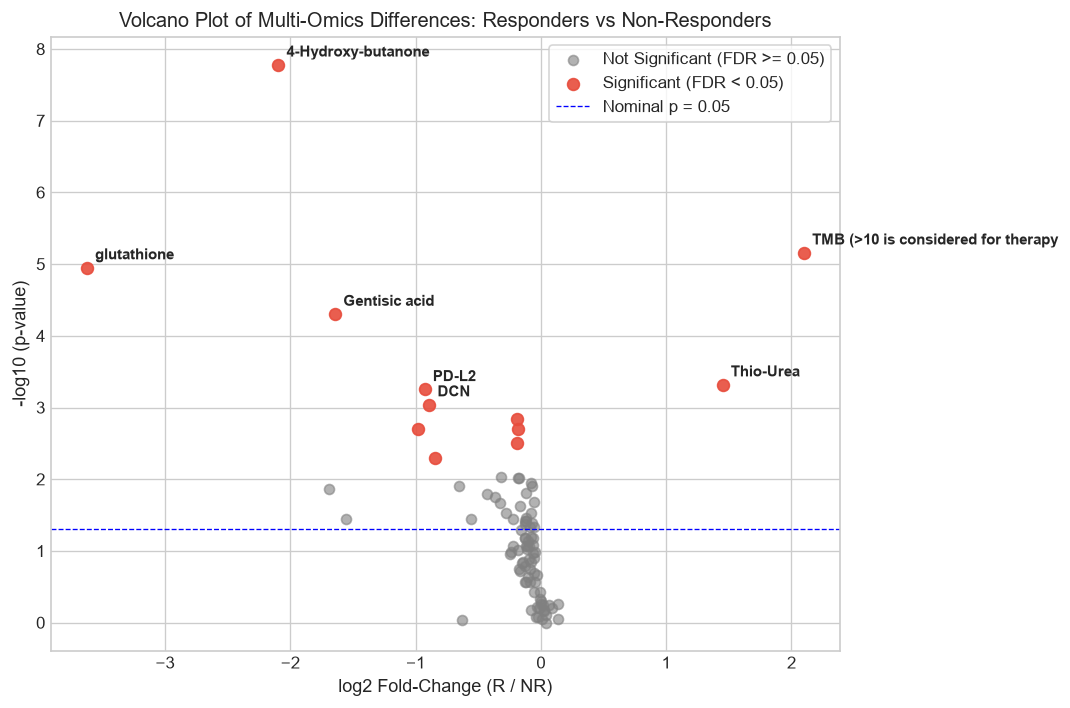

In [10]:
# Volcano Plot
fig, ax = plt.subplots(figsize=(9, 6))

res_df['neg_log10_p'] = -np.log10(res_df['p_value'])
sig_features = res_df[res_df['fdr_bh'] < 0.05]
nonsig_features = res_df[res_df['fdr_bh'] >= 0.05]

ax.scatter(nonsig_features['log2FC'], nonsig_features['neg_log10_p'], color='grey', alpha=0.6, label='Not Significant (FDR >= 0.05)')
ax.scatter(sig_features['log2FC'], sig_features['neg_log10_p'], color='#e74c3c', alpha=0.9, s=50, label='Significant (FDR < 0.05)')

# Annotate top 8 features
for _, row in res_df.head(8).iterrows():
    if not np.isnan(row['log2FC']):
        ax.annotate(row['feature'], (row['log2FC'], row['neg_log10_p']), 
                    fontsize=9, weight='bold', xytext=(5, 5), textcoords='offset points')

ax.axhline(-np.log10(0.05), color='blue', linestyle='--', linewidth=0.8, label='Nominal p = 0.05')
ax.set_title('Volcano Plot of Multi-Omics Differences: Responders vs Non-Responders')
ax.set_xlabel('log2 Fold-Change (R / NR)')
ax.set_ylabel('-log10 (p-value)')
ax.legend(frameon=True)
plt.tight_layout()
plt.show()


## 7. Critical Discovery: Run-Order / Batch Drift & Outcome Confounding
### The Problem:
1. The spreadsheet is organized sequentially: Samples 1 to 20 are **100% Non-Responders**, whereas Samples 43 to 64 are **100% Responders**.
2. If an analytical platform (mass spectrometer or multiplex immunoassay) experiences signal drift, column fouling, or antibody decay over run time, **run order becomes perfectly confounded with response**.
3. We test whether markers drift monotonically with `sample ` order **within** each response group independently.


=== Metabolomics Run-Order Correlation within Non-Responders (n=30) ===
                 marker  spearman_r        p_val
     4-Hydroxy-butanone    0.802892 9.366866e-08
              Thio-Urea   -0.764627 8.689377e-07
            glutathione    0.702781 1.489894e-05
          Gentisic acid    0.623582 2.318159e-04
Sphingosine 1-phosphate   -0.559066 1.320402e-03
=== Metabolomics Run-Order Correlation within Responders (n=34) ===
                 marker  spearman_r        p_val
              Thio-Urea   -0.846295 2.893019e-10
            glutathione    0.759817 1.872871e-07
Sphingosine 1-phosphate   -0.707257 2.917225e-06
          Gentisic acid    0.629947 6.545918e-05
     4-Hydroxy-butanone    0.607028 1.409824e-04


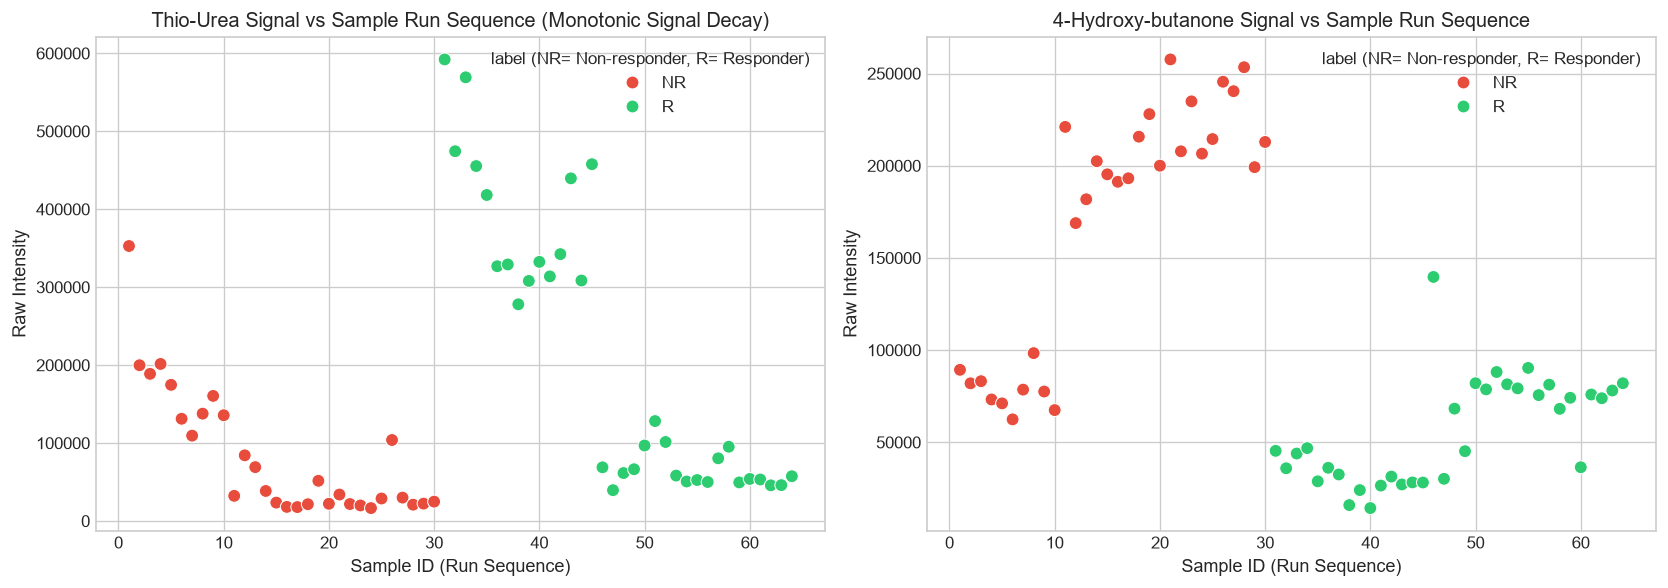

In [11]:
# Within-group correlation with Sample ID
for grp_name, grp in [('Non-Responders (n=30)', nr_group), ('Responders (n=34)', r_group)]:
    corrs = []
    sid = grp.iloc[:, 0]
    for col in metab_cols:
        r, p = stats.spearmanr(sid, grp[col])
        corrs.append({'marker': col, 'spearman_r': r, 'p_val': p})
    c_df = pd.DataFrame(corrs).sort_values('p_val')
    print(f"=== Metabolomics Run-Order Correlation within {grp_name} ===")
    print(c_df.to_string(index=False))

# Plotting the run drift across the cohort
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Thio-Urea drift
sns.scatterplot(data=df_raw, x='sample ', y='Thio-Urea', hue=label_col, palette=['#e74c3c', '#2ecc71'], s=60, ax=axes[0])
axes[0].set_title('Thio-Urea Signal vs Sample Run Sequence (Monotonic Signal Decay)')
axes[0].set_xlabel('Sample ID (Run Sequence)')
axes[0].set_ylabel('Raw Intensity')

# 4-Hydroxy-butanone drift
sns.scatterplot(data=df_raw, x='sample ', y='4-Hydroxy-butanone', hue=label_col, palette=['#e74c3c', '#2ecc71'], s=60, ax=axes[1])
axes[1].set_title('4-Hydroxy-butanone Signal vs Sample Run Sequence')
axes[1].set_xlabel('Sample ID (Run Sequence)')
axes[1].set_ylabel('Raw Intensity')

plt.tight_layout()
plt.show()


## 8. Unsupervised Dimension Reduction: Principal Component Analysis (PCA)
Evaluating the multi-omics feature space (92 proteins + 5 metabolites) using PCA to inspect cohort separation and variance structure.


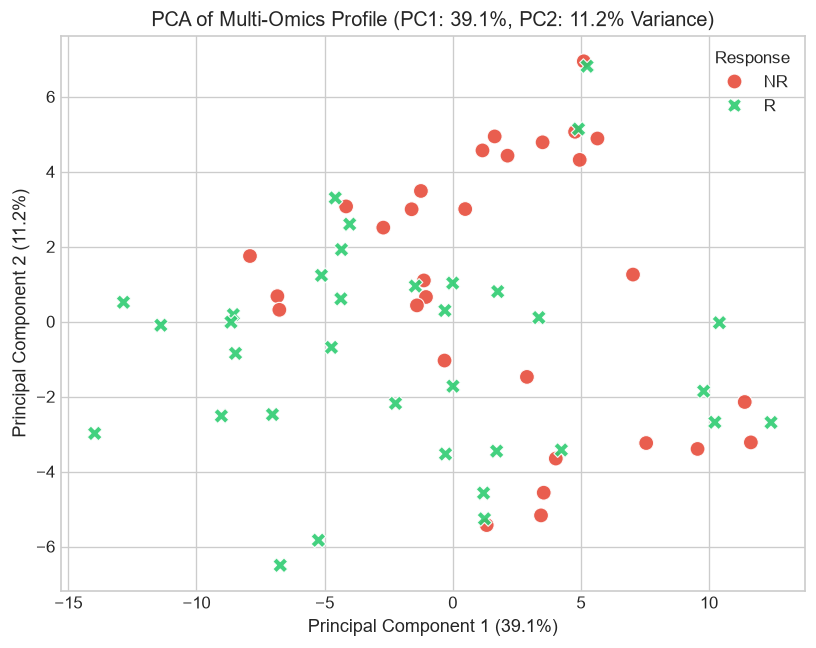

In [12]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

omics_matrix = df_raw[metab_cols + prot_cols].values
scaled_omics = StandardScaler().fit_transform(omics_matrix)

pca = PCA(n_components=2)
coords = pca.fit_transform(scaled_omics)

pca_df = pd.DataFrame({
    'PC1': coords[:, 0],
    'PC2': coords[:, 1],
    'Response': df_raw[label_col],
    'Sample_ID': df_raw['sample ']
})

fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=pca_df, x='PC1', y='PC2', hue='Response', style='Response',
                palette=['#e74c3c', '#2ecc71'], s=80, alpha=0.9, ax=ax)

ax.set_title(f'PCA of Multi-Omics Profile (PC1: {pca.explained_variance_ratio_[0]*100:.1f}%, PC2: {pca.explained_variance_ratio_[1]*100:.1f}% Variance)')
ax.set_xlabel(f'Principal Component 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)')
ax.set_ylabel(f'Principal Component 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)')
plt.show()


## 9. Comprehensive Data Quality Summary & Cleaning Protocol

### Summary of Identified Issues:
1. **Critical Clinical Inconsistency:** 4 patients exhibit $PFS > OS$ (Pts 1, 21, 28, 53). In oncological data, progression must precede or coincide with death.
2. **Methodological Run-Order Confounding:** High correlation between `sample ` sequence and metabolomic intensities (e.g., Thio-Urea $r = -0.85$, Glutathione $r = +0.76$) confounded with response-sorted spreadsheet layout.
3. **Data Entry Errors:** 
   - `non-veg.` contains `'1\`'` in Sample 40.
   - `sex` contains trailing whitespace `'F '` in Sample 10.
   - 8 patients have $|BMI_{rec} - BMI_{calc}| > 1.0\text{ kg/m}^2$, with up to +7.4 error in Pt 39.
4. **Survey Contradiction:** 31 patients recorded as both `Veg. == 1` and `non-veg. == 1`.
5. **Histology Ambiguity:** Histology columns are non-mutually exclusive (8 patients have multiple flags, 7 have zero flags).
6. **Laboratory Sum Inconsistency:** Leukocyte differential sums reach up to 159.6% post-therapy.
7. **High-Dimensional Overfitting Risk:** $p = 144$ features for $n = 64$ samples ($p/n = 2.25$).

### Recommended Preprocessing Protocol Before Modeling:
- **Header Cleaning:** Strip all whitespace and standardize to snake_case.
- **Type Correction:** Cast `sex` to clean category, recode `'1\`'` to 1 in `non-veg.`.
- **BMI Standardization:** Replace recorded BMI with dynamically computed float: $weight / (height/100)^2$.
- **Survival Data Adjudication:** Re-verify clinical charts for the 4 patients where $PFS > OS$.
- **Batch Normalization:** Apply run-order detrending (e.g., LOESS or spline correction) to metabolomics data.
- **Modeling Discipline:** Always perform randomized cross-validation; **never** use sample sequence as a feature.
